# ETGEM添加外源2,3-BDO反应

In [5]:
import sys
sys.path.append(r'./ETGEM/etgems_web/')
from ETGEM.etgems_web.script.io.json import *
from ETGEM.etgems_web.script.io.convert import *
from ETGEM.etgems_web.script.tcmodel.construct import *
import pandas as pd
import numpy as np
import cobra
import copy
import re
cobra_config = cobra.Configuration()
cobra_config.solver = "glpk"

In [6]:
def reaction_create(rxn_id, name, lower_bound, upper_bound, metabolites, kcat=1000000, kcat_MW=1000000,notes={},annotation={},mw=3600000,g0=0): 
    return {"id": rxn_id, "name": name, "lower_bound": lower_bound, "upper_bound": upper_bound, \
    "metabolites": metabolites, "kcat": kcat, "kcat_MW": kcat_MW, "mw": mw, "notes": notes, "annotation": annotation, "g0": g0, "objective_coefficient": 0}

aldC_kcat = 500
spont_kcat = 1000000
bdh_kcat = 400

rxn27664 = reaction_create('rxn27664','Acetolactate synthase',0,1000,{"cpd00020_c0":-2.0,"cpd00067_c0":-1.0,"cpd00011_c0":1.0,"cpd00668_c0":1.0})
rxn15383 = reaction_create('rxn15383','(S)-2-Hydroxy-2-methyl-3-oxobutanoate carboxy-lyase',0,1000
,{"cpd00067_c0":-1.0,"cpd00668_c0":-1.0,"cpd00011_c0":1.0,"cpd00361_c0":1.0}, kcat=aldC_kcat, kcat_MW=aldC_kcat)
rxn01685 = reaction_create('rxn01685','Acetoin:NAD+ oxidoreductase',0,1000
,{"cpd00003_c0":-1.0,"cpd00361_c0":-1.0,"cpd00004_c0":1.0,"cpd00067_c0":1.0,"cpd00551_c0":1.0}, kcat=spont_kcat, kcat_MW=spont_kcat)
rxn01685_reverse = reaction_create('rxn01685_reverse','Acetoin:NAD+ oxidoreductase',0,1000
,{"cpd00003_c0":1.0,"cpd00361_c0":1.0,"cpd00004_c0":-1.0,"cpd00067_c0":-1.0,"cpd00551_c0":-1.0}, kcat=spont_kcat, kcat_MW=spont_kcat)
rxn11219 = reaction_create('rxn11219','spontaneous reaction',0,1000
,{"cpd00007_c0":-1.0, "cpd00668_c0":-1.0, "cpd00011_c0":1.0, "cpd00551_c0":1.0}, kcat=spont_kcat, kcat_MW=spont_kcat)
rxn02112 = reaction_create('rxn02112','(R,R)-Butane-2,3-diol:NAD+ oxidoreductase',0,1000,{"cpd00003_c0":-1.0,"cpd01947_c0":-1.0,"cpd00004_c0":1.0,"cpd00067_c0":1.0,"cpd00361_c0":1.0}
, kcat=bdh_kcat, kcat_MW=bdh_kcat)
rxn02112_reverse = reaction_create('rxn02112_reverse','(R,R)-Butane-2,3-diol:NAD+ oxidoreductase',0,1000,{"cpd00003_c0":1.0,"cpd01947_c0":1.0,"cpd00004_c0":-1.0,"cpd00067_c0":-1.0,"cpd00361_c0":-1.0}
, kcat=bdh_kcat, kcat_MW=bdh_kcat)
EX_23BDO_e = reaction_create('EX_23BDO_e','EX_23BDO_e',0,1000,{"cpd01947_c0":-1.0})
EX_ACTN_e = reaction_create('EX_ACTN_e','EX_ACTN_e',0,1000,{"cpd00361_c0":-1.0})

bdo_rxnlist = [rxn27664, rxn15383, rxn01685, rxn01685_reverse, rxn11219, rxn02112, rxn02112_reverse, EX_23BDO_e,EX_ACTN_e]

In [7]:
cpd00551_c0 = {
      "id": "cpd00551_c0",
      "name": "DIACETYL",
      "compartment": "c",
      "charge": 0,
      "formula": "C4H6O2",
      "concentration_ub": -3.912023005,
      "concentration_lb": -14.50865774,
      "annotation": {
        "AraCyc": "DIACETYL",
        "CornCyc": "DIACETYL",
        "KEGG": "C00741",
        "MetaCyc": "DIACETYL",
        "Name": "2,3-Butanedione; 2,3-butanedione; 2,3-diketobutane; 2,3-dioxobutane; Biacetyl; DTYL; Diacetyl; Dimethylglyoxal; biacetyl; butadione; butanedione; diacetyl; dimethyl diketone; dimethylglyoxal",
        "bigg.metabolite": "diact"
      }
    }
cpd01947_c0 = {
      "id": "cpd01947_c0",
      "name": "(R,R)-2,3-Butanediol",
      "compartment": "c",
      "charge": 0,
      "formula": "C4H10O2",
      "concentration_ub": -3.912023005,
      "concentration_lb": -14.50865774,
      "annotation": {
        "EcoCyc": "BUTANEDIOL",
        "KEGG": "C03044",
        "MaizeCyc": "BUTANEDIOL",
        "MetaCyc": "BUTANEDIOL",
        "Name": "(R,R)-2,3-Butanediol; (R,R)-2,3-Butylene glycol; (R,R)-2,3-butanediol; (R,R)-2,3-butylene glycol; (R,R)-Butane-2,3-diol; (R,R)-butane-2,3-diol; 2,3-butanediol; 2,3-butylene glycol; BDOH; D(-)-2,3-butanediol; butanediol",
        "bigg.metabolite": "btd_RR"
      }
    }
bdo_metlist = [cpd00551_c0,cpd01947_c0]
print(bdo_metlist)

[{'id': 'cpd00551_c0', 'name': 'DIACETYL', 'compartment': 'c', 'charge': 0, 'formula': 'C4H6O2', 'concentration_ub': -3.912023005, 'concentration_lb': -14.50865774, 'annotation': {'AraCyc': 'DIACETYL', 'CornCyc': 'DIACETYL', 'KEGG': 'C00741', 'MetaCyc': 'DIACETYL', 'Name': '2,3-Butanedione; 2,3-butanedione; 2,3-diketobutane; 2,3-dioxobutane; Biacetyl; DTYL; Diacetyl; Dimethylglyoxal; biacetyl; butadione; butanedione; diacetyl; dimethyl diketone; dimethylglyoxal', 'bigg.metabolite': 'diact'}}, {'id': 'cpd01947_c0', 'name': '(R,R)-2,3-Butanediol', 'compartment': 'c', 'charge': 0, 'formula': 'C4H10O2', 'concentration_ub': -3.912023005, 'concentration_lb': -14.50865774, 'annotation': {'EcoCyc': 'BUTANEDIOL', 'KEGG': 'C03044', 'MaizeCyc': 'BUTANEDIOL', 'MetaCyc': 'BUTANEDIOL', 'Name': '(R,R)-2,3-Butanediol; (R,R)-2,3-Butylene glycol; (R,R)-2,3-butanediol; (R,R)-2,3-butylene glycol; (R,R)-Butane-2,3-diol; (R,R)-butane-2,3-diol; 2,3-butanediol; 2,3-butylene glycol; BDOH; D(-)-2,3-butanediol; 

In [8]:
json_path = "./model/ETiZM564_MM_optimized.json"
model_json = json_load(json_path)
model_json['reactions'].extend(bdo_rxnlist)
model_json['metabolites'].extend(bdo_metlist)   
etmodel_MM_23BDO_path = "./model/ETiZM564_MM_optimized_23BDO.json"
with open(etmodel_MM_23BDO_path,"w")as wf:
    json.dump(model_json,wf,indent=2)


In [9]:
json_path = "./model/ETiZM564_MM015_optimized.json"
model_json = json_load(json_path)
model_json['reactions'].extend(bdo_rxnlist)
model_json['metabolites'].extend(bdo_metlist)   
etmodel_MM015_23BDO_path = "./model/ETiZM564_MM015_optimized_23BDO.json"
with open(etmodel_MM015_23BDO_path,"w")as wf:
    json.dump(model_json,wf,indent=2)


# 酶热模型模拟23BDO微氧条件产量最高

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
matplotlib.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['font.size'] = 12
import sys
sys.path.append(r'./ETGEM/etgems_web/')
import ETGEM.etgems_web.script
from ETGEM.etgems_web.script.io.json import *
from ETGEM.etgems_web.script.analysis.flux_balance_analysis import *
import pyomo.environ as pyo
from ETGEM.etgems_web.script.analysis.flux_balance_analysis import calculate_ETM
import cobra
cobra.Configuration.solver='gurobi'

# 创建列表存储数据
data = {
    'o2_uptake': [],
    'biomass': [],
    'glucose': [],
    'bdo': [],
    'acetoin': [],
    'aldc': [],
    'o2_q10': [],
    'o2_rxn': []
}

max_bdo = 1000
beta = 1
for i in range(0,21,2):
    model = read_json_model("./model/ETiZM564_MM_optimized_23BDO.json")
    model.obj_name = "ZM_BIOMASS"
    model.add_medium("EX_glc_D_e",0)

    for rxn in model.reactions:
        if "ZMO1360" in model.get_reaction_by_id(rxn).gene_reaction_rule:
            model.get_reaction_by_id(rxn).bounds = (0,0)
    model.add_medium("EX_glc_D_e_reverse",100)
    model.get_reaction_by_id('EX_glc_D_e').bounds = (0,0)

    for o2rxn in ["rxn00262",'rxn00208']:
        model.get_reaction_by_id(o2rxn).bounds = (0,0)
    
    model.add_medium("EX_o2_e_reverse",i)
    model.get_reaction_by_id("EX_o2_e_reverse").bounds = (0,i)
    model.get_reaction_by_id("rxn37453").kcat = 15
    model.get_reaction_by_id("rxn37453").kcat_MW = 15

    alpha = max_bdo*1.3 - i * beta
    def make_rule(a,m):
        def rule(m):
            return m.reaction['rxn02112_reverse'] <= a
        return rule
    custom_constraints = {
        'bio_limit': make_rule(alpha,model)
    }
    result = calculate_ETM(model, "maximize", 0, custom_constraints=custom_constraints)
    
    if i==0:
        model.obj_name = "EX_23BDO_e"
        max_bdo_result = calculate_ETM(model, "maximize", 0, custom_constraints=custom_constraints)
        max_bdo = max_bdo_result.reaction['EX_23BDO_e'].value
        
    # 保存数据
    data['o2_uptake'].append(i)
    data['biomass'].append(result.reaction['ZM_BIOMASS'].value)
    data['glucose'].append(result.reaction['EX_glc_D_e_reverse'].value)
    data['bdo'].append(result.reaction['EX_23BDO_e'].value)
    data['acetoin'].append(result.reaction['EX_actn__S_e'].value + result.reaction['EX_ACTN_e'].value)
    data['aldc'].append(result.reaction['rxn15383'].value)
    data['o2_q10'].append(result.reaction['rxn37453'].value)
    data['o2_rxn'].append(result.reaction['rxn11219'].value)
    
    print(f"生长={result.reaction['ZM_BIOMASS'].value:.3f} | "
          f"葡萄糖={result.reaction['EX_glc_D_e_reverse'].value:.3f} | "
          f"BDO={result.reaction['EX_23BDO_e'].value:.3f} | "
          f"Acetoin={result.reaction['EX_actn__S_e'].value + result.reaction['EX_ACTN_e'].value:.3f} | "
          f"Aldc={result.reaction['rxn15383'].value:.3f} | "
          f"o2_uptake={result.reaction['EX_o2_e_reverse'].value:.3f} | "
          f"o2_q10={result.reaction['rxn37453'].value:.3f} | "    # q10 respiratory chain
          f"O2_rxn={result.reaction['rxn11219'].value:.3f}")      # spontaneous reaction

# 转换为DataFrame
df = pd.DataFrame(data)

# 保存数据到CSV文件
df.to_csv('simulation_results.csv', index=False)
print("\n数据已保存到 simulation_results.csv")

生长=0.036 | 葡萄糖=23.191 | BDO=22.912 | Acetoin=0.000 | Aldc=22.912 | o2_uptake=0.000 | o2_q10=0.000 | O2_rxn=0.000
生长=0.043 | 葡萄糖=23.815 | BDO=23.474 | Acetoin=0.000 | Aldc=21.474 | o2_uptake=2.000 | o2_q10=0.000 | O2_rxn=2.000
生长=0.051 | 葡萄糖=24.440 | BDO=24.037 | Acetoin=0.000 | Aldc=20.038 | o2_uptake=4.000 | o2_q10=0.000 | O2_rxn=4.000
生长=0.059 | 葡萄糖=25.065 | BDO=24.601 | Acetoin=0.000 | Aldc=18.601 | o2_uptake=6.000 | o2_q10=0.000 | O2_rxn=6.000
生长=0.066 | 葡萄糖=24.971 | BDO=24.439 | Acetoin=0.000 | Aldc=16.505 | o2_uptake=8.000 | o2_q10=0.066 | O2_rxn=7.934
生长=0.070 | 葡萄糖=23.007 | BDO=22.439 | Acetoin=0.000 | Aldc=12.758 | o2_uptake=10.000 | o2_q10=0.319 | O2_rxn=9.681
生长=0.075 | 葡萄糖=21.042 | BDO=20.439 | Acetoin=0.000 | Aldc=9.011 | o2_uptake=12.000 | o2_q10=0.572 | O2_rxn=11.428
生长=0.079 | 葡萄糖=19.077 | BDO=18.439 | Acetoin=0.000 | Aldc=5.264 | o2_uptake=14.000 | o2_q10=0.824 | O2_rxn=13.175
生长=0.082 | 葡萄糖=17.668 | BDO=16.439 | Acetoin=0.571 | Aldc=2.054 | o2_uptake=16.000 | o2_q10=1

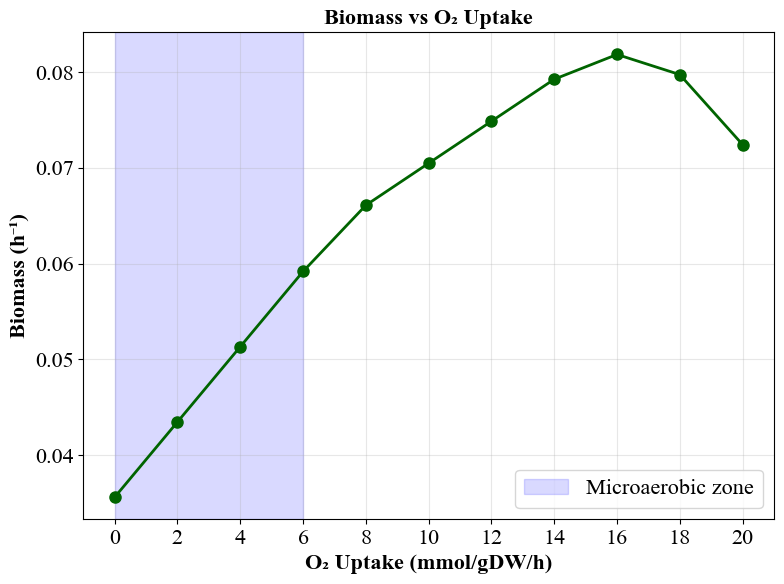

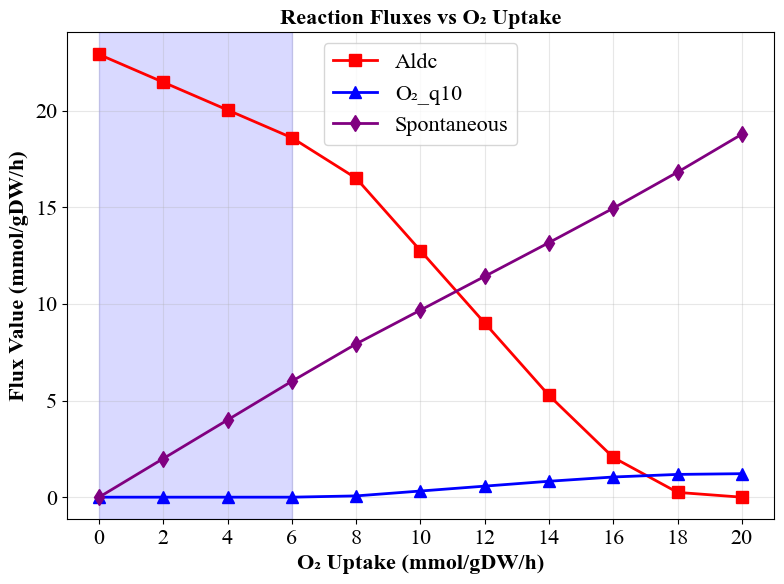

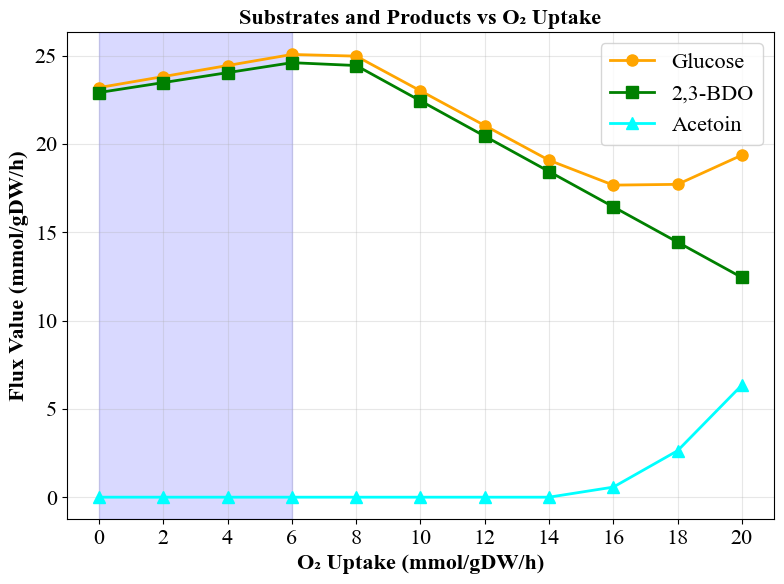


三个图已分别保存为:
  Figure1_Biomass.png
  Figure2_Reaction_Fluxes.png
  Figure3_Substrates_Products.png

数据统计:
BDO最高产量: 24.60 at O₂ uptake = 6
Biomass最高值: 0.082 at O₂ uptake = 16


In [11]:
# ========== 图1: Biomass vs O2_uptake ==========
fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1.plot(df['o2_uptake'], df['biomass'], 'o-', color='darkgreen', linewidth=2, markersize=8)
ax1.set_xlabel('O₂ Uptake (mmol/gDW/h)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax1.set_ylabel('Biomass (h⁻¹)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax1.set_title('Biomass vs O₂ Uptake', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(range(0, 21, 2))
ax1.tick_params(labelsize=16)
for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_fontname('Times New Roman')
ax1.axvspan(0, 6, alpha=0.15, color='blue', label='Microaerobic zone')
ax1.legend(prop={'family': 'Times New Roman', 'size': 16})
plt.tight_layout()
plt.savefig('Figure1_Biomass.png', dpi=300, bbox_inches='tight')
plt.show()

# ========== 图2: Aldc, O2_q10, O2_rxn vs O2_uptake ==========
fig2, ax2 = plt.subplots(figsize=(8, 6))
ax2.plot(df['o2_uptake'], df['aldc'], 's-', color='red', linewidth=2, markersize=8, label='Aldc')
ax2.plot(df['o2_uptake'], df['o2_q10'], '^-', color='blue', linewidth=2, markersize=8, label='O₂_q10')
ax2.plot(df['o2_uptake'], df['o2_rxn'], 'd-', color='purple', linewidth=2, markersize=8, label='Spontaneous')
ax2.set_xlabel('O₂ Uptake (mmol/gDW/h)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax2.set_ylabel('Flux Value (mmol/gDW/h)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax2.set_title('Reaction Fluxes vs O₂ Uptake', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(range(0, 21, 2))
ax2.tick_params(labelsize=16)
for label in ax2.get_xticklabels() + ax2.get_yticklabels():
    label.set_fontname('Times New Roman')
ax2.legend(loc='best', prop={'family': 'Times New Roman', 'size': 16})
ax2.axvspan(0, 6, alpha=0.15, color='blue')
plt.tight_layout()
plt.savefig('Figure2_Reaction_Fluxes.png', dpi=300, bbox_inches='tight')
plt.show()

# ========== 图3: Glucose, BDO, Acetoin vs O2_uptake ==========
fig3, ax3 = plt.subplots(figsize=(8, 6))
ax3.plot(df['o2_uptake'], df['glucose'], 'o-', color='orange', linewidth=2, markersize=8, label='Glucose')
ax3.plot(df['o2_uptake'], df['bdo'], 's-', color='green', linewidth=2, markersize=8, label='2,3-BDO')
ax3.plot(df['o2_uptake'], df['acetoin'], '^-', color='cyan', linewidth=2, markersize=8, label='Acetoin')
ax3.set_xlabel('O₂ Uptake (mmol/gDW/h)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax3.set_ylabel('Flux Value (mmol/gDW/h)', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax3.set_title('Substrates and Products vs O₂ Uptake', fontsize=16, fontweight='bold', fontname='Times New Roman')
ax3.grid(True, alpha=0.3)
ax3.set_xticks(range(0, 21, 2))
ax3.tick_params(labelsize=16)
for label in ax3.get_xticklabels() + ax3.get_yticklabels():
    label.set_fontname('Times New Roman')
ax3.legend(loc='best', prop={'family': 'Times New Roman', 'size': 16})
ax3.axvspan(0, 6, alpha=0.15, color='blue')
plt.tight_layout()
plt.savefig('Figure3_Substrates_Products.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n三个图已分别保存为:")
print(f"  Figure1_Biomass.png")
print(f"  Figure2_Reaction_Fluxes.png")
print(f"  Figure3_Substrates_Products.png")
print(f"\n数据统计:")
print(f"BDO最高产量: {df['bdo'].max():.2f} at O₂ uptake = {df.loc[df['bdo'].idxmax(), 'o2_uptake']}")
print(f"Biomass最高值: {df['biomass'].max():.3f} at O₂ uptake = {df.loc[df['biomass'].idxmax(), 'o2_uptake']}")